# Assignment 2
## Group B: K-Nearest Neighbours (KNN)
### Ivan Bibat
#### L00167791@atu.ie

## What is KNN?

KNN is a classification algorithm which predicts values based on:

- The distance from the new point to all the points in the training set.
- Picks the K closest points (nearest neighbours).
- Majority vote: The most common class in the K-nearest neighbours is the prediction.

KNN does no 'real' training, which is why it's known as a lazy learner. It stores all the training data and all the work is done at the time of inference.

Is it possible to identify a penguin species from its body measurements with KNN?

In [2]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

## 1. The dataset

The Palmer Penguins dataset is a collection of measurements of around 350 penguins of 3 distinct species recorded in Antarctica.

The penguins measurements in the dataset that will be used as features for KNN will be the bill length/depth, flipper length, and body mass.

In [9]:
df = pd.read_csv("../data/penguins.csv")
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df = df.dropna(subset=features)

In [10]:
print(df.info())

<class 'pandas.DataFrame'>
Index: 342 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            342 non-null    str    
 1   island             342 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 21.4 KB
None


In [11]:
print(f"Penguins: {len(df)}")
print(df['species'].value_counts())
df[features + ['species']].head()

Penguins: 342
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
4,36.7,19.3,193.0,3450.0,Adelie
5,39.3,20.6,190.0,3650.0,Adelie


The Gentoo is easiest to distinguish based on the existing features in the dataset, it is mostly separated from the features of other species in the set, shown below.

The Gentoo typically has a shallower bill, longer flippers, and is heavier than the other two species based on the data.

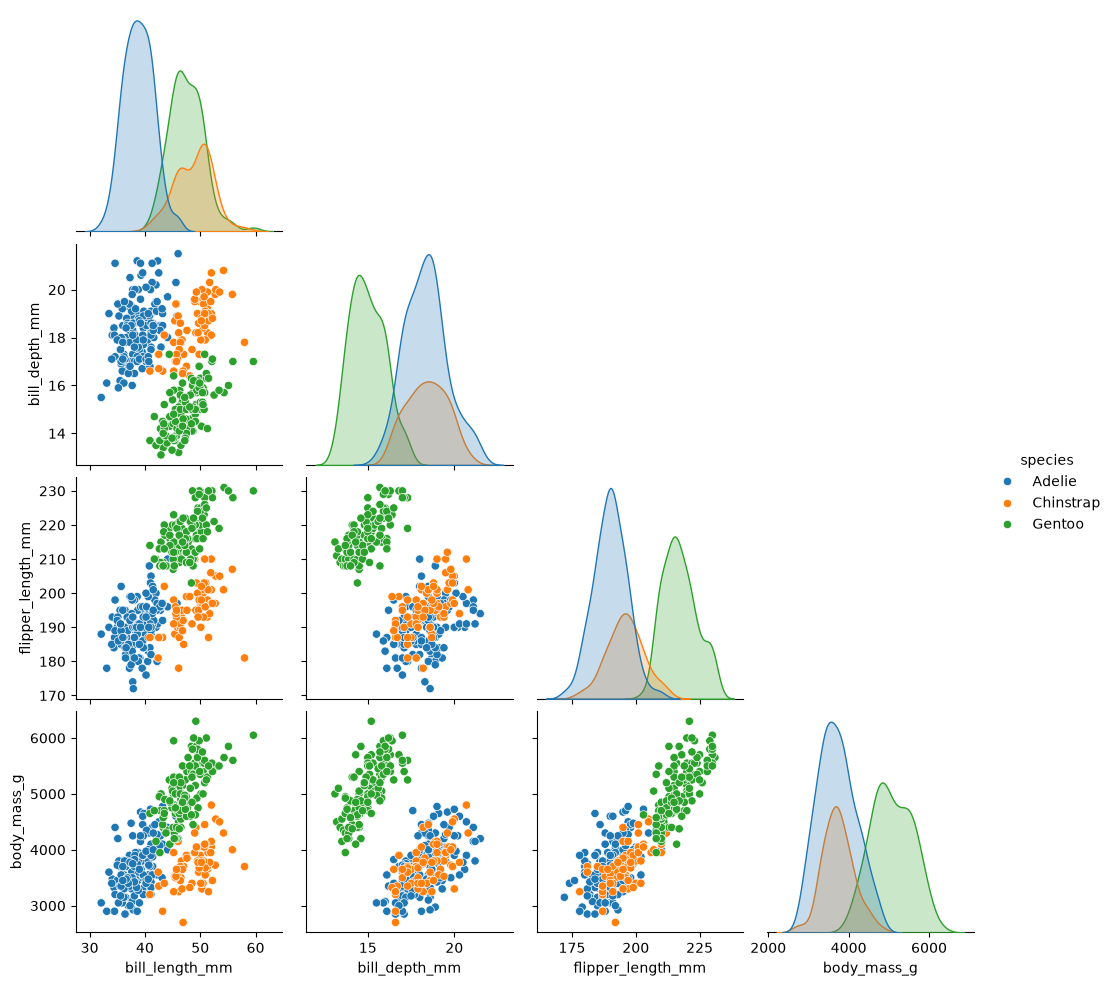

In [12]:
sns.pairplot(df, vars=features, hue='species', corner=True)
plt.show()

## 2. Splitting the dataset
The dataset will be split 75/25 between training and testing.

KNN will use the training set by storing it and searching for neighbours.
The test set will be used to measure the accuracy of the model on unseen data.

`stratify = y` maintains species proportions in each set, which is needed due to the different quantities of each species in the dataset.

In [13]:
X = df[features]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Training penguins: {len(X_train)}")
print(f"Test penguins:     {len(X_test)}")


Training penguins: 256
Test penguins:     86


## 3. Scaling for KNN

KNN bases its predictions on the distance between features.

The features in the dataset vary in terms of units used, and without scaling these features, for example, a 500g difference in body mass would dwarf a bill depth of 5mm difference, making the KNN model focus mainly on the body mass rather than considering both proportionally.

This is fixed using StandardScaler, which scales every feature to have a mean of 0 and std of 1, so each feature is considered equally.

In [15]:
X_train.describe().loc[['min', 'max', 'std']].round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
min,33.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0
std,5.5,2.0,13.8,794.2


Scaling makes such a big difference in accuracy, as without it, the body mass is the main feature used to distinguish species. Adelie and Chinstrap species weigh similarly, so the model gets confused with the prediction in this case.

After scaling the features, the bill length can be used as the distinguishing feature betweeen the two species.

In [17]:
k = 5

unscaled_knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
unscaled_acc = accuracy_score(y_test, unscaled_knn.predict(X_test))

scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
scaled_acc = accuracy_score(y_test, scaled_knn.predict(X_test))

print(f"Accuracy without scaling: {unscaled_acc:.1%}")
print(f"Accuracy with scaling:    {scaled_acc:.1%}")

Accuracy without scaling: 79.1%
Accuracy with scaling:    100.0%


## 4. Choosing the k value
k is the amount of neighbours that vote for the final prediction. 

- Small k value
Setting a small k value to eg. 1 means that KNN predictions depend on only the 1 nearest penguin. If those penguins are outliers, the prediction will be wrong. The model will be prone to overfitting to noise in the data.

- Large k value
Setting a large k value eg. 100 will include penguins that are very far away, with different species. The more prominent species will start winning every vote, and the model has underfitted.

- To choose the correct k value
5-fold cross-validation can be used to determine k fairly, against the training set. The training set is separated into 5 parts, 4 of which is used to train the model and the last to test it. This is repeated 5 times in total so each part is tested once.

The average of these 5 scores is more reliable than using just one test split.

In [ ]:
k_values = range(1, 102, 2)
cv_scores = []

for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_train, y_train, cv=5)
    cv_scores.append(scores.mean())

best_k = k_values[np.argmax(cv_scores)]
print(f"Best k: {best_k}  (cross-validated accuracy {max(cv_scores):.1%})")


Best k: 3  (cross-validated accuracy 99.2%)


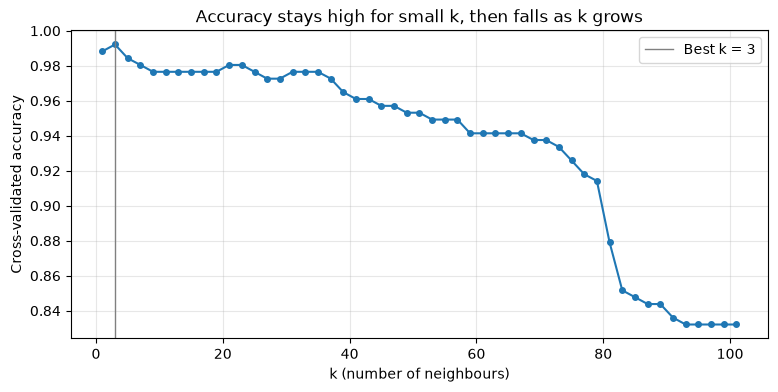

In [21]:
plt.figure(figsize=(9, 4))
plt.plot(k_values, cv_scores, marker='o', markersize=4)
plt.axvline(best_k, color='grey', linewidth=1, label=f'Best k = {best_k}')
plt.xlabel('k (number of neighbours)')
plt.ylabel('Cross-validated accuracy')
plt.title('Accuracy stays high for small k, then falls as k grows')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The accuracy peaks at k value 3, plateaus, then drops as the k value is increased against the data. This is indicative of the neighbours being included in the vote being far away and of different species. The number of the majority species in the set trumps the vote of the minority species, causing a bias of voting towards the majority.

Chinstraps are the smallest group with 51 in total in the training set, with 41 in the cross-validation fold. As the k value increases, the other votes HAVE to come from the other species, outvoting the chinstraps.

An odd k value make the chance of a vote being split 50/50 between species less likely to happen.

## 5. Final model evaluation

The best k value 3 found through 5-fold cross-validation is used in the final model.
It's trained on the full training dataset and evaluated on unseen data (test set) once.

In [ ]:
final_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_knn.fit(X_train, y_train)
y_pred = final_knn.predict(X_test)
print(f"Test accuracy (k = {best_k}): {accuracy_score(y_test, y_pred):.1%}\n")
print(classification_report(y_test, y_pred))


Test accuracy (k = 3): 98.8%

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.99        38
   Chinstrap       0.94      1.00      0.97        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           0.99        86
   macro avg       0.98      0.99      0.99        86
weighted avg       0.99      0.99      0.99        86



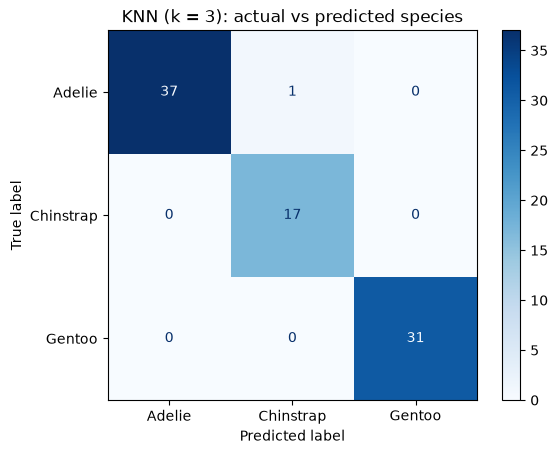

In [23]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title(f'KNN (k = {best_k}): actual vs predicted species')
plt.grid(False)
plt.show()

Based on the confusion matrix, the model correctly predicted the species of penguin 85 (37+17+31) out of 86 times, with 1 Adelie penguin being misclassified as a Chinstrap. This matches the initial observation of Chinstraps and Adelies having very similar features, except for the bill length.

## 6. KNN decision-making

The last KNN uses 4 features (4-dimensional) which can't be drawn. To visualise the KNN, a model is trained on just the bill length and depth, the two features that distinguished the three species the best in the data.

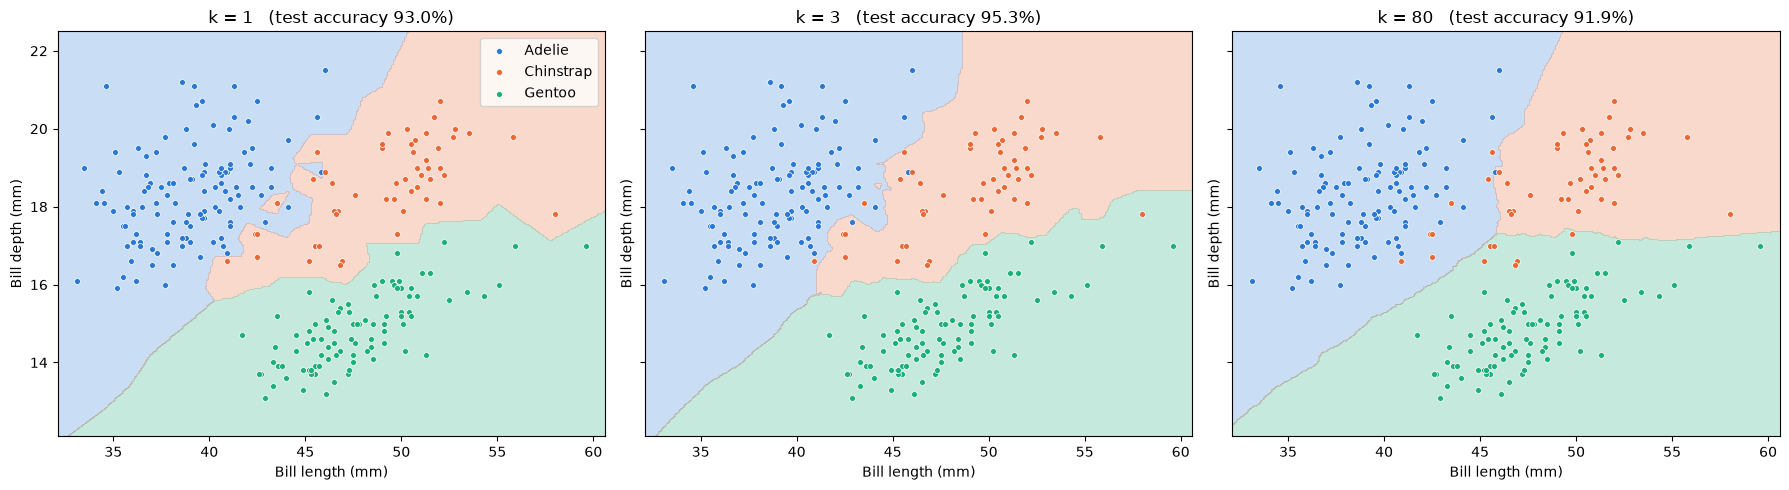

In [33]:
two_features = ['bill_length_mm', 'bill_depth_mm']
colours = {'Adelie': '#2a78d6', 'Chinstrap': '#eb6834', 'Gentoo': '#1baf7a'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, k in zip(axes, [1, best_k, 80]):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train[two_features], y_train)
    acc = accuracy_score(y_test, model.predict(X_test[two_features]))

    # Shade the background by the species KNN predicts at every point on a grid
    DecisionBoundaryDisplay.from_estimator(
        model, X_train[two_features], ax=ax,
        response_method='predict', grid_resolution=300, alpha=0.25,
        multiclass_colors=[colours[s] for s in model.classes_],
        xlabel='Bill length (mm)', ylabel='Bill depth (mm)',
    )

    # Draw the real training penguins on top
    for species, colour in colours.items():
        points = X_train[y_train == species]
        ax.scatter(
            points['bill_length_mm'], 
            points['bill_depth_mm'],
            s=18, 
            color=colour, 
            edgecolor='white', 
            linewidth=0.5, 
            label=species)

    ax.set_title(f'k = {k}   (test accuracy {acc:.1%})')

axes[0].legend()
plt.tight_layout()
plt.show()

At k = 1, you can see the model following every single penguin, creating jagged boundaries and creating small isolated islands to fit each penguin to the correct species, indicating overfitting.

At k = 3, the boundaries are smoother and generally following the clusters of different species correctly, indicating a good balance of bias and variance, giving it the ideal score against the test set.
The accuracy here is 95% instead of 99% as only 2 features are used, and flipper length/body mass are not considered in this model to differentiate the species.

At k = 80, the boundaries are very smooth and don't seem to follow any sort of pattern, indicating underfitting against the test set.



## 7. Conclusion

- KNN finds the k-nearest penguins in the training set and predicts based on the majority vote.

- Scaling is required as body mass would dictate the distance between datapoints. Scaling allows each feature to matter equally. Accuracy of the model grew from 79.1% to 100% with scaling.

- 5-fold cross validation matched k = 3 as the best k value at 99.2%. A small k value overfit to the training set, and larger k values underfits as longer distance species with higher quantities in the set outvote the minority species.

- The model accurately predicts 98.8% of the time the species of penguins on unseen data in the test set. an Adelie penguin was predicted as a Chinstrap once, the two species whose features overlap quite strongly.